In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression 
from sklearn.linear_model import SGDClassifier 
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.metrics import accuracy_score



df = pd.read_csv("C:\\Users\\Admin\\OneDrive\\Documents\\Telecom_chrun predictor\\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [4]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [5]:
df.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
df.info

<bound method DataFrame.info of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL 

In [7]:
df["InternetService"].unique()
for index,col in enumerate(df.columns):
        print(f"{col} = {df[col].unique()}")

customerID = ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender = ['Female' 'Male']
SeniorCitizen = [0 1]
Partner = ['Yes' 'No']
Dependents = ['No' 'Yes']
tenure = [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
PhoneService = ['No' 'Yes']
MultipleLines = ['No phone service' 'No' 'Yes']
InternetService = ['DSL' 'Fiber optic' 'No']
OnlineSecurity = ['No' 'Yes' 'No internet service']
OnlineBackup = ['Yes' 'No' 'No internet service']
DeviceProtection = ['No' 'Yes' 'No internet service']
TechSupport = ['No' 'Yes' 'No internet service']
StreamingTV = ['No' 'Yes' 'No internet service']
StreamingMovies = ['No' 'Yes' 'No internet service']
Contract = ['Month-to-month' 'One year' 'Two year']
PaperlessBilling = ['Yes' 'No']
PaymentMethod = ['Electronic check' 'Mailed check' 'Bank tr

In [8]:
for index,col in enumerate(df.columns):
   print(f"  {df.columns[index]} = {df[col].dtype}")

  customerID = object
  gender = object
  SeniorCitizen = int64
  Partner = object
  Dependents = object
  tenure = int64
  PhoneService = object
  MultipleLines = object
  InternetService = object
  OnlineSecurity = object
  OnlineBackup = object
  DeviceProtection = object
  TechSupport = object
  StreamingTV = object
  StreamingMovies = object
  Contract = object
  PaperlessBilling = object
  PaymentMethod = object
  MonthlyCharges = float64
  TotalCharges = object
  Churn = object


In [9]:

df.iloc[6754]["TotalCharges"]

# df.iloc[753]["TotalCharges"]

' '

In [10]:
columns = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity',
           'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
           'StreamingMovies', 'PaperlessBilling', 'Churn']
for col in columns :
    
    df[col] = df[col].replace({'No phone service': 'No', 'No internet service': 'No'})
    df[col] = df[col].map({"Yes": 1, "No": 0})
    


df.head()

df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [11]:
df["gender"]  = df["gender"].map({"Male": 1 , "Female": 0})
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,0,DSL,0,...,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,5575-GNVDE,1,0,0,0,34,1,0,DSL,1,...,1,0,0,0,One year,0,Mailed check,56.95,1889.5,0
2,3668-QPYBK,1,0,0,0,2,1,0,DSL,1,...,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,7795-CFOCW,1,0,0,0,45,0,0,DSL,1,...,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,0,0,0,0,2,1,0,Fiber optic,0,...,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


In [12]:
columns = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity',
           'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
           'StreamingMovies', 'PaperlessBilling', 'Churn', 'TotalCharges']

for col in columns:
    df[col]= df[col].replace(" ",0)
    df[col] =  pd.to_numeric(df[col],errors = "coerce")

df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
df.isna().sum()[df.isna().sum() > 0]

Series([], dtype: int64)

In [14]:
df[df.isna().any(axis=1)]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [15]:
for index,col in enumerate(df.columns):
   print(f"  {df.columns[index]} = {df[col].dtype}")

  customerID = object
  gender = int64
  SeniorCitizen = int64
  Partner = int64
  Dependents = int64
  tenure = int64
  PhoneService = int64
  MultipleLines = int64
  InternetService = object
  OnlineSecurity = int64
  OnlineBackup = int64
  DeviceProtection = int64
  TechSupport = int64
  StreamingTV = int64
  StreamingMovies = int64
  Contract = object
  PaperlessBilling = int64
  PaymentMethod = object
  MonthlyCharges = float64
  TotalCharges = float64
  Churn = int64


In [16]:
df = df.drop("customerID", axis = 1)

In [17]:
df.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [18]:
#UNIVARIATE ANALYSIS
numeric_col =  ["TotalCharges","MonthlyCharges","tenure"]

for col in numeric_col:
    print(df[col].describe())
    print(f"Skewness {df[col].skew()}")

count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64
Skewness 0.963234654832277
count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64
Skewness -0.22052443394398033
count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64
Skewness 0.2395397495619829


<Axes: ylabel='Frequency'>

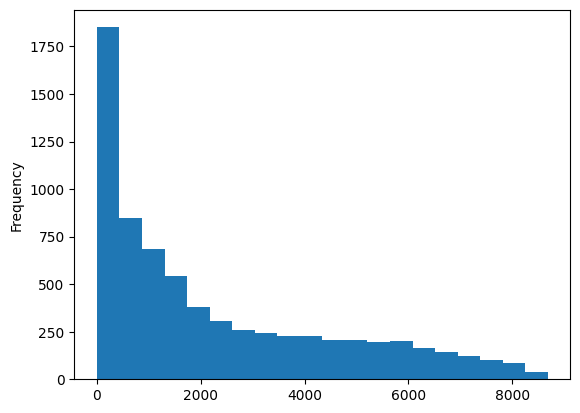

In [19]:
df["TotalCharges"].plot(kind = 'hist',bins = 20)

<Axes: ylabel='Frequency'>

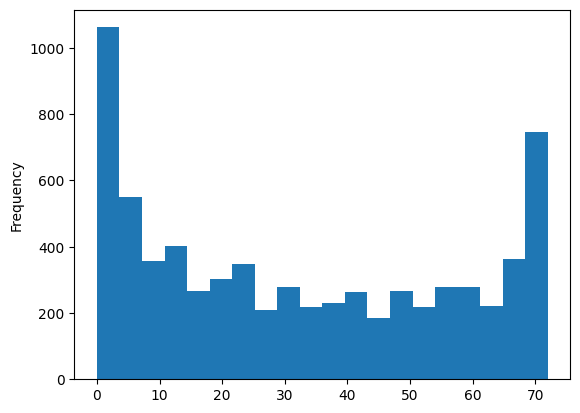

In [20]:
df["tenure"].plot(kind = 'hist',bins = 20)

<Axes: ylabel='Density'>

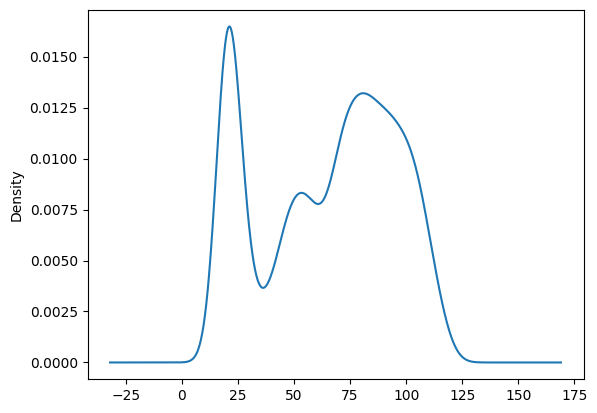

In [21]:
df["MonthlyCharges"].plot(kind = 'kde')

<Axes: ylabel='Frequency'>

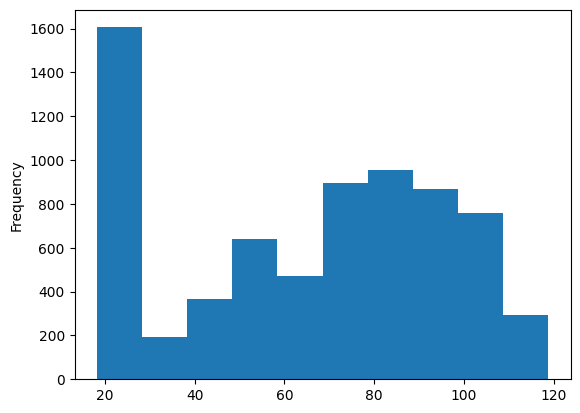

In [22]:
df["MonthlyCharges"].plot(kind = "hist")

<Axes: >

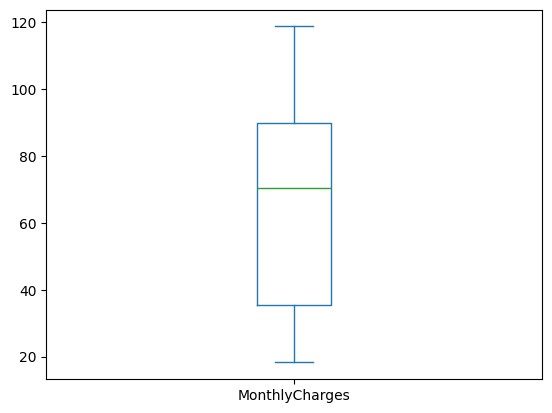

In [23]:
df["MonthlyCharges"].plot(kind = "box")

<Axes: >

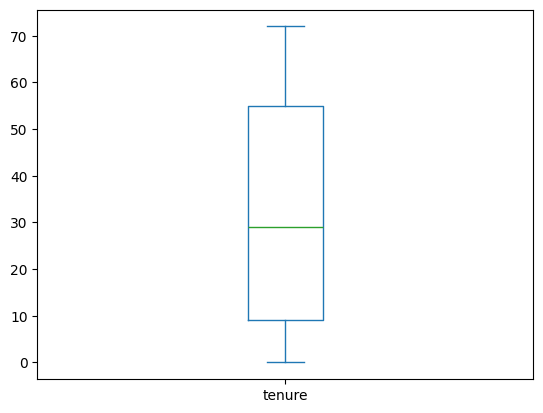

In [24]:
df["tenure"].plot(kind = "box")

****CONCLUSION :  TENURE IS SOMEWHERE NORMALLY DISTRUBUTED
               NO OUTLIERS AND MISSING VALUE 
             THE PLAN  HAVING MINIMUM COST  AND MINIMUM TENURE IS MOST LIKED BY PEOPLE****
  ****             

In [25]:
#CATGORICAL UNIVARITE ANALYSIS 
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


<Axes: xlabel='InternetService'>

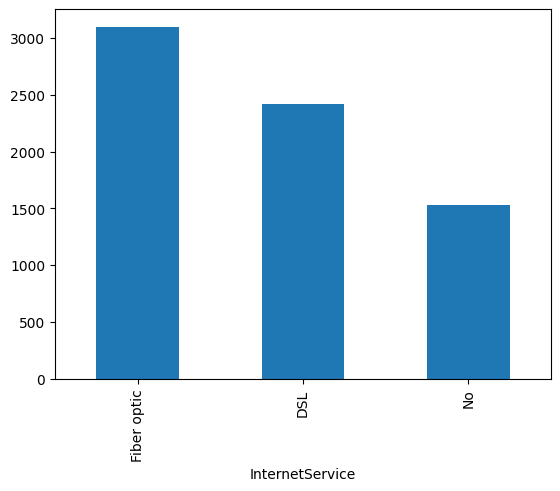

In [26]:
df["InternetService"].value_counts().plot(kind = "bar")

<Axes: xlabel='Contract'>

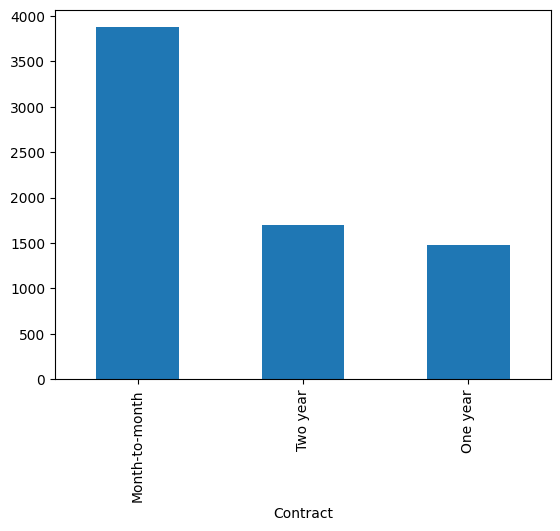

In [27]:

df["Contract"].value_counts().plot(kind = "bar")

<Axes: xlabel='PaymentMethod'>

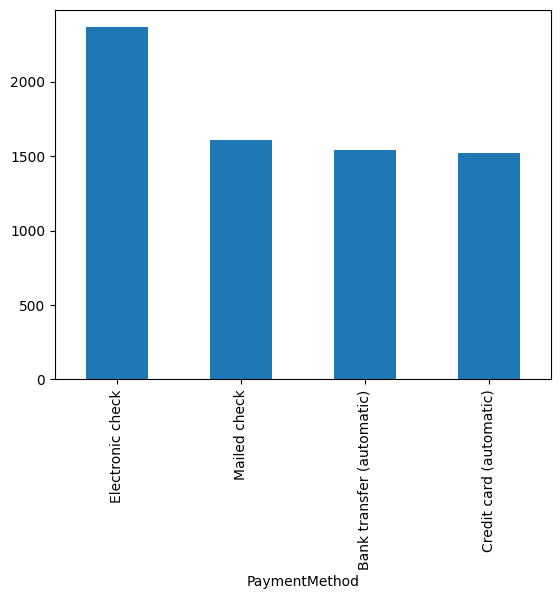

In [28]:

df["PaymentMethod"].value_counts().plot(kind = "bar")

<Axes: ylabel='count'>

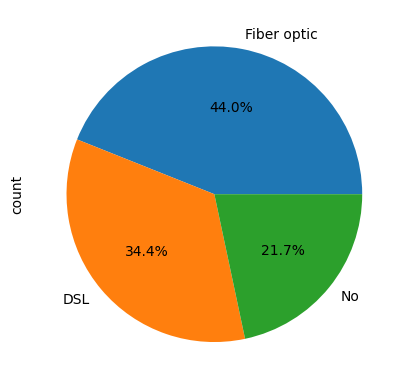

In [29]:
df["InternetService"].value_counts().plot(kind = "pie",autopct = "%.01f%%")

<Axes: ylabel='count'>

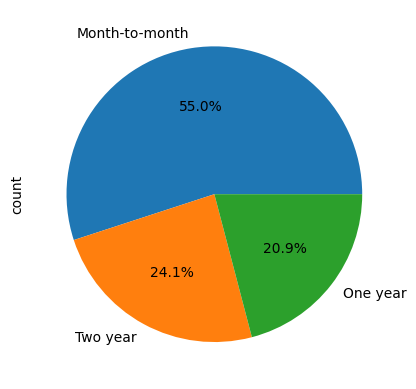

In [30]:
df["Contract"].value_counts().plot(kind = "pie",autopct = "%.01f%%")

> ****CONCLUSION : most people prefer month to month contract ,fiber optic internet service is loved among people****

In [31]:
# BIVARIATE ANALYISIS


**BIVARIATE ANALYSIS**
**both numerical**
scatter 2d hist or kde plot 
**both categorical**
generate a crosstable
heatmaps stacked bar and tree plots 
**num and cat**
bar box sctter kde 

In [32]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


In [33]:
pd.crosstab(df["gender"],df["Churn"])

Churn,0,1
gender,,
0,2549,939
1,2625,930


<Axes: xlabel='Churn', ylabel='gender'>

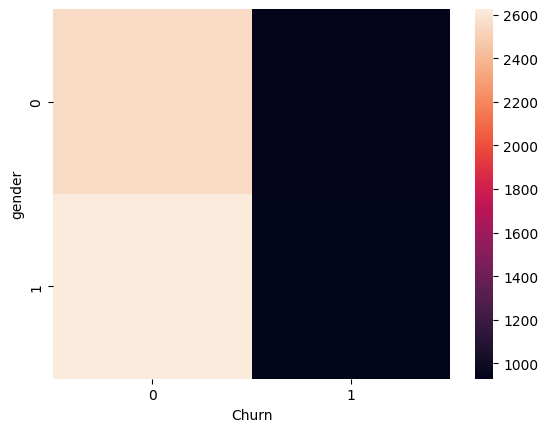

In [34]:
#both categorical
sns.heatmap(pd.crosstab(df["gender"],df["Churn"]))

<Axes: xlabel='Churn', ylabel='Partner'>

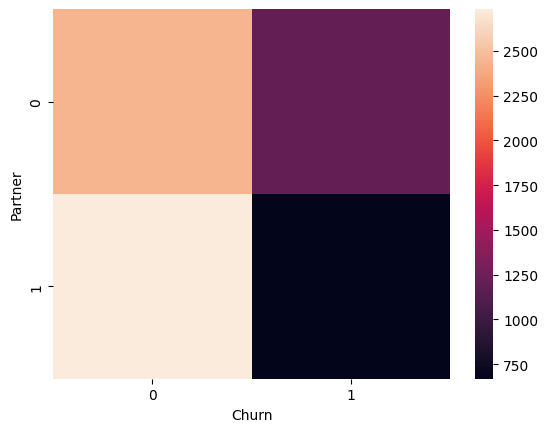

In [35]:
sns.heatmap(pd.crosstab(df["Partner"],df["Churn"]))

In [36]:
pd.crosstab(df["Partner"],df["Churn"])

Churn,0,1
Partner,,
0,2441,1200
1,2733,669


In [37]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


patner nhi hai toh leave  karne ke chances kam 


<function matplotlib.pyplot.show(close=None, block=None)>

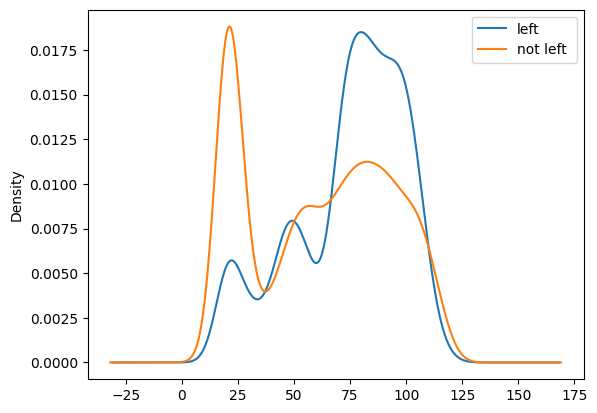

In [38]:
# numerical and catogrical 

df[df["Churn"] == 1]["MonthlyCharges"].plot(kind="kde",label = "left")
df[df["Churn"] == 0]["MonthlyCharges"].plot(kind="kde",label = "not left ")
plt.legend()
plt.show


**with increasing monthly charges the chances of leaveing increases**

<function matplotlib.pyplot.show(close=None, block=None)>

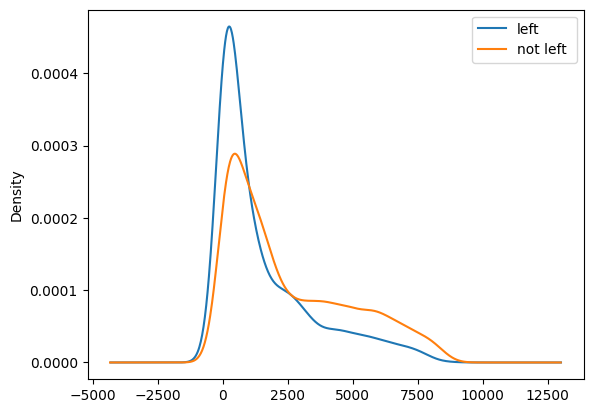

In [39]:
df[df["Churn"] == 1]["TotalCharges"].plot(kind="kde",label = "left")
df[df["Churn"] == 0]["TotalCharges"].plot(kind="kde",label = "not left ")
plt.legend()
plt.show


In [40]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


****FEATURE ENG****  IN THIS WE WILL MAKE ONE FEATUER OF THIS   protection count (OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport ka sum)  AND OF streaming count (StreamingTV, StreamingMovie ) ALSO ONE FEATURE WE WILL ADD OF total services count.

In [41]:
df["Protection_count"] = df["OnlineSecurity"]+df["OnlineBackup"]+ df["DeviceProtection"]+ df["TechSupport"]
df["Stream_count"] = df["StreamingTV"] + df["StreamingMovies"] 
df["Total_services"] = df["StreamingTV"] + df["StreamingMovies"] +df["OnlineSecurity"]+df["OnlineBackup"]+ df["DeviceProtection"]+ df["TechSupport"]
drop_col = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport","StreamingTV", "StreamingMovies"]
for col in drop_col:
    df = df.drop(col,axis=1)

In [42]:
df.head(4)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Protection_count,Stream_count,Total_services
0,0,0,1,0,1,0,0,DSL,Month-to-month,1,Electronic check,29.85,29.85,0,1,0,1
1,1,0,0,0,34,1,0,DSL,One year,0,Mailed check,56.95,1889.50,0,2,0,2
2,1,0,0,0,2,1,0,DSL,Month-to-month,1,Mailed check,53.85,108.15,1,2,0,2
3,1,0,0,0,45,0,0,DSL,One year,0,Bank transfer (automatic),42.30,1840.75,0,3,0,3


In [43]:
#now analyis of data set again 
print(pd.crosstab(df["SeniorCitizen"],df["Churn"]))


Churn             0     1
SeniorCitizen            
0              4508  1393
1               666   476


In [44]:
print(pd.crosstab(df["Partner"],df["Churn"]))

Churn       0     1
Partner            
0        2441  1200
1        2733   669


<function matplotlib.pyplot.show(close=None, block=None)>

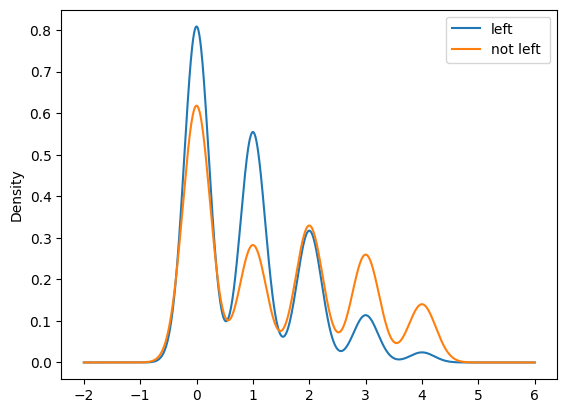

In [45]:
df[df["Churn"] == 1]["Protection_count"].plot(kind="kde",label = "left")
df[df["Churn"] == 0]["Protection_count"].plot(kind="kde",label = "not left ")
plt.legend()
plt.show


<function matplotlib.pyplot.show(close=None, block=None)>

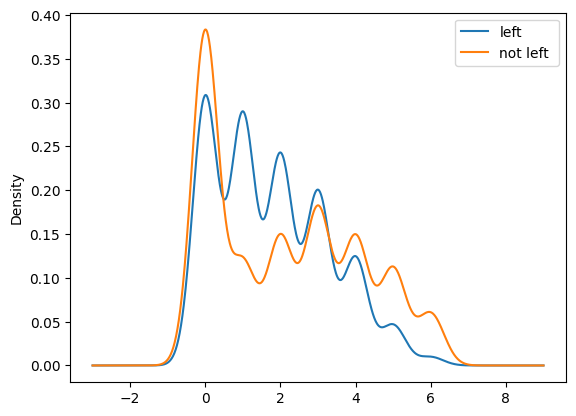

In [46]:
df[df["Churn"] == 1]["Total_services"].plot(kind="kde",label = "left")
df[df["Churn"] == 0]["Total_services"].plot(kind="kde",label = "not left ")
plt.legend()
plt.show


<function matplotlib.pyplot.show(close=None, block=None)>

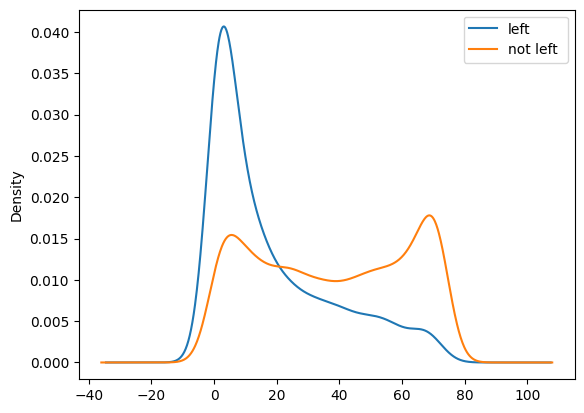

In [47]:
df[df["Churn"] == 1]["tenure"].plot(kind="kde",label = "left")
df[df["Churn"] == 0]["tenure"].plot(kind="kde",label = "not left ")
plt.legend()
plt.show

In [48]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Protection_count,Stream_count,Total_services
0,0,0,1,0,1,0,0,DSL,Month-to-month,1,Electronic check,29.85,29.85,0,1,0,1
1,1,0,0,0,34,1,0,DSL,One year,0,Mailed check,56.95,1889.50,0,2,0,2
2,1,0,0,0,2,1,0,DSL,Month-to-month,1,Mailed check,53.85,108.15,1,2,0,2
3,1,0,0,0,45,0,0,DSL,One year,0,Bank transfer (automatic),42.30,1840.75,0,3,0,3
4,0,0,0,0,2,1,0,Fiber optic,Month-to-month,1,Electronic check,70.70,151.65,1,0,0,0


In [49]:


fig = px.scatter_3d(
    df,
    x="MonthlyCharges",
    y="TotalCharges",
    z="Total_services",
    color="Churn",
)
fig.update_traces(marker=dict(size=4))
fig.show()

In [50]:


fig = px.scatter(
    df,
    x="MonthlyCharges",
    y="TotalCharges",
    color="Churn",
    opacity=0.6,
)
fig.update_traces(marker=dict(size=4))
fig.show()

In [51]:


fig = px.scatter(
    df,
    x="MonthlyCharges",
    y="tenure",
    color="Churn",
    opacity=0.6,
)
fig.update_traces(marker=dict(size=4))
fig.show()

In [52]:
print(df.groupby("Churn")[["MonthlyCharges", "tenure", "TotalCharges"]].mean())
print(df[["MonthlyCharges", "tenure", "TotalCharges", "Churn"]].corr()["Churn"])

       MonthlyCharges     tenure  TotalCharges
Churn                                         
0           61.265124  37.569965   2549.911442
1           74.441332  17.979133   1531.796094
MonthlyCharges    0.193356
tenure           -0.352229
TotalCharges     -0.198324
Churn             1.000000
Name: Churn, dtype: float64


**High monthly charges + low tenure = high churn risk.**

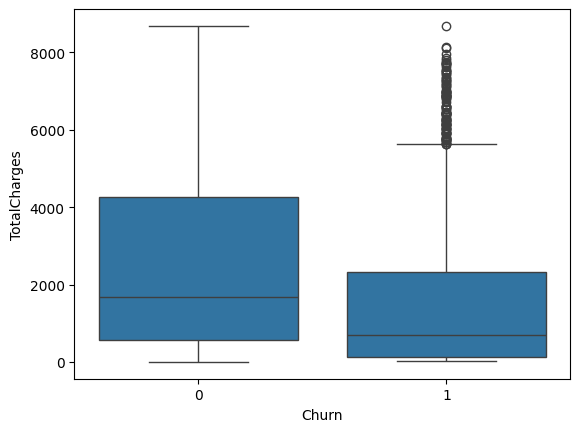

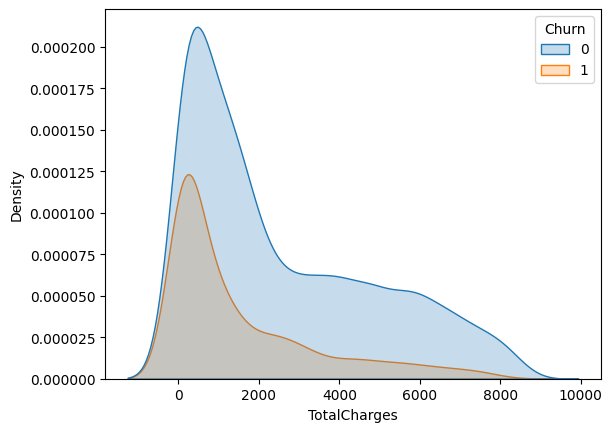

Churn
0    2549.911442
1    1531.796094
Name: TotalCharges, dtype: float64


In [53]:


sns.boxplot(x="Churn", y="TotalCharges", data=df)
plt.show()

sns.kdeplot(data=df, x="TotalCharges", hue="Churn", fill=True)
plt.show()


print(df.groupby("Churn")["TotalCharges"].mean())

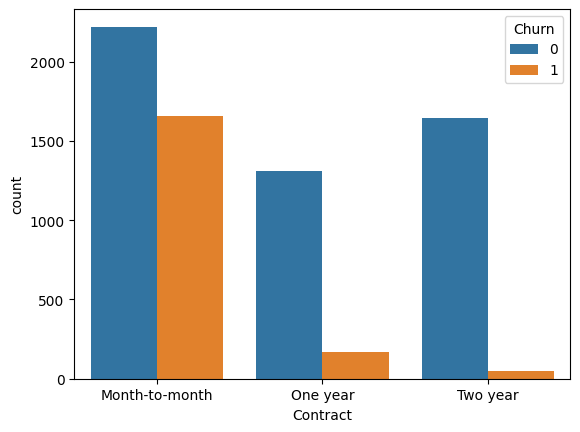

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64


In [54]:
sns.countplot(x="Contract", hue="Churn", data=df)
plt.show()

print(df.groupby("Contract")["Churn"].mean())

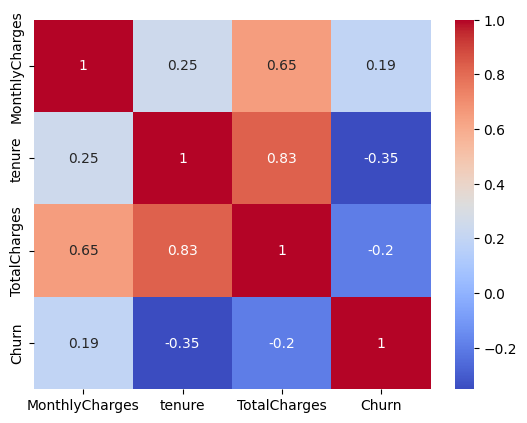

In [55]:
sns.heatmap(df[["MonthlyCharges", "tenure", "TotalCharges", "Churn"]].corr(), annot=True, cmap="coolwarm")
plt.show()

**Main feature  : tenure , monthly cost , contarct**

In [56]:
df["Churn"] = df.pop("Churn")

In [57]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Protection_count,Stream_count,Total_services,Churn
0,0,0,1,0,1,0,0,DSL,Month-to-month,1,Electronic check,29.85,29.85,1,0,1,0
1,1,0,0,0,34,1,0,DSL,One year,0,Mailed check,56.95,1889.50,2,0,2,0
2,1,0,0,0,2,1,0,DSL,Month-to-month,1,Mailed check,53.85,108.15,2,0,2,1
3,1,0,0,0,45,0,0,DSL,One year,0,Bank transfer (automatic),42.30,1840.75,3,0,3,0
4,0,0,0,0,2,1,0,Fiber optic,Month-to-month,1,Electronic check,70.70,151.65,0,0,0,1


In [58]:
x_train , x_test ,y_train ,y_test = train_test_split(df.iloc[:,:-1],df.iloc[:,-1],test_size = .2 )

In [59]:
X = df.drop("Churn", axis=1)
y = df["Churn"]
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()


In [60]:

trf = ColumnTransformer(
    transformers=[
        ('trf1', StandardScaler(), num_cols),
        ('trf2', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
    ],
    remainder='passthrough')

pipe = Pipeline([
    ('preprocess', trf),                      
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

pipe.fit(x_train, y_train)
y_prob = pipe.predict_proba(x_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)


y_pred = pipe.predict(x_test)

In [61]:
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       0.92      0.73      0.81      1031
           1       0.52      0.82      0.64       378

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

ROC-AUC: 0.8495489045925515


In [62]:
pipe = Pipeline([
    ('preprocess', trf),
    ('model', SGDClassifier(max_iter=1000, learning_rate="constant", eta0=0.01, random_state=42))
])

pipe.fit(x_train, y_train)
y_pred = pipe.predict(x_test)

In [63]:
print(accuracy_score(y_pred,y_test))

0.8005677785663591
